### Simulador Destilador Flash Isotermico 0823

Este Notebook tiene como objetivo diseñar un simulador de destilacion Flash para una mezcla dada

<center><img src=Diagrama.png width="250" class='center'></center>

#### Ecuaciones Caracteristicas de un Flash

Balance general de Flash
$$F=L+V$$

Balance por componente
$$Fz_{i}=Lx_{i}+Vy_{i}$$

Constante de equilibrio
$$K_{i}=\frac{y_{i}}{x_{i}}$$  

Condiciones de restricción
$$\sum x_{i} -\sum y_{i}= 0$$

Fracciones
$$x_{i} = \frac{z_{i}}{1+\varphi(k_{i}-1)}$$

$$y_{i} = k_{i}x_{i}$$

Ecuacion de Rachford - Rise
$$\sum \frac{z_{i}(1-k_{i})}{1+\varphi(k_{i}-1)} = 0$$

$$0<\varphi<1$$

$$\varphi = \frac{V}{F}$$


___

#### Mezcla 1

100 Kmol/h
- Benceno 60% (b)
- Tolueno 25% (t)
- O-Xileno 15% (x)

A 1 atm de presión y 100°C

___

Se importan las librerías que se van a utilizar

In [1]:
import numpy as np
import sympy as smp
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pd.options.display.float_format = '{:,.4f}'.format

Se declaran los datos que nos da el problema

In [3]:
F = 100 #kmol/h
zb = 0.6
zt = 0.25
zx = 0.15

P = 760 #mmHg
T = 100 #°C

Cálculo de Ks con la Ecuación de Antoane

$$log_{10}(P^{s}_{l})=A-\frac{B}{T+C}$$

$$ K_{i} = \frac{P^{s}_{l}}{P_{T}} $$

Se declaran las constantes de Antoane para cada componente de la mezcla

In [4]:
cte_ant_b = np.array([6.87987, 1196.76, 219.161])
cte_ant_t = np.array([6.95087, 1342.31, 219.187])
cte_ant_x = np.array([7.00154, 1476.393, 213.872])

Se programa la ecuación como una función

In [5]:
def antoan(A,B,C,T):
    return 10**(A-(B/(T+C)))

Se calculan las presiones 

In [6]:
Psb = antoan(cte_ant_b[0],cte_ant_b[1],cte_ant_b[2],T)
Pst = antoan(cte_ant_t[0],cte_ant_t[1],cte_ant_t[2],T)
Psx = antoan(cte_ant_x[0],cte_ant_x[1],cte_ant_x[2],T)

Se calculan las constantes de equilibrio

In [7]:
kb = Psb / P
kt = Pst / P
kx = Psx / P

Se resuelve la ecuación de Richford-Rise para este sistema

$$f(\varphi)=\frac{z_{b}(1-k_{b})}{1+\varphi(k_{b}-1)} + \frac{z_{t}(1-k_{t})}{1+\varphi(k_{t}-1)}+ \frac{z_{x}(1-k_{x})}{1+\varphi(k_{x}-1)}= 0$$

In [8]:
fhi = smp.symbols('fhi')

In [9]:
f = (zb*(1-kb))/(1+fhi*(kb-1)) + (zt*(1-kt))/(1+fhi*(kt-1)) + (zx*(1-kx))/(1+fhi*(kx-1))

In [10]:
sol = smp.solve(f,fhi)

Ahora se guarda la variable y se combierte a Type Floa64, ya que sympy por defecno nos arroja Objects

In [11]:
phi = np.float64(sol[0])
phi

0.680225840521602

Se calculan los flujos V y L

In [12]:
V = F * phi
L = F - V

Se programa $x_{i}$ como una función

In [13]:
def x(z,k,phi):
    return z / (1+(phi*(k-1)))

Se calculan $x_{i}$ y $y_{i}$

In [14]:
xb = x(zb,kb,phi)
xt = x(zt,kt,phi)
xx = x(zx,kx,phi)

In [15]:
yb = xb * kb
yt = xt * kt
yx = xx * kx

Se presentan los resultados

In [16]:
print(f'V = {V:0.3f} kmol/h \n yb = {yb:0.3f}\n yt = {yt:0.3f}\n yx = {yx:0.3f}\n')
print(f'L = {L:0.3f} kmol/h \n xb = {xb:0.3f}\n xt = {xt:0.3f}\n xx = {xx:0.3f}\n')

V = 68.023 kmol/h 
 yb = 0.697
 yt = 0.224
 yx = 0.079

L = 31.977 kmol/h 
 xb = 0.393
 xt = 0.306
 xx = 0.302



In [17]:
index = ['F','V','L']
columns = ['Flujos (kmol/h)','Benceno','Tolueno','O-Xileno']
datos = ([F,zb,zt,zx],
         [V,yb,yt,yx],
         [L,xb,xt,xx])

df = pd.DataFrame(datos, columns=columns, index=index)
df

,Flujos (kmol/h),Benceno,Tolueno,O-Xileno
F,100.0000,0.6000,0.2500,0.1500
V,68.0226,0.6974,0.2238,0.0788
L,31.9774,0.3928,0.3057,0.3016


___

#### Mezcla 2

1000 lbmol/h son alimentados a  $T = 90°F$ y $P = 75 psia$ un destilador flash con la siguiente composición
- Metano - 286 lbmol/h
- Etano - 157 lbmol/h
- Propano - 240 lbmol/h
- n-Butano - 169 lbmol/h
- n-Pentano - 148 lbmol/h

In [18]:
F = 1000 #Lbmol
zm = 286 / 1000
ze = 157 / 1000
zp = 240 / 1000
zb = 169 / 1000
znp = 148 / 1000

Calcular ks con relaciones de equilibrio a 75 psias

$$k = K_{1}+K_{2}T+K_{3}T^{2}+K_{4}T^{3}$$

Los datos termodinámicos son dados en una hoja de Excel, por lo que hay que leerlos

In [19]:
pd.read_excel('Datos Mezcla 2.xlsx').tail(1)

,Componente,K1,K2*(10^4),K3*(10^5),K4*(10^8)
7,NaN,",",NaN,NaN,NaN


Se limpia eL DataFrame

In [20]:
kdf = pd.read_excel('Datos Mezcla 2.xlsx').drop(index=[5,6,7]).set_index('Componente')
kdf

,K1,K2*(10^4),K3*(10^5),K4*(10^8)
Componente,,,,
Metano,12.2500,0.2500,-0.0006,0.0000
Etano,4.7500,-0.0004,0.0002,-0.0000
Propano,2.3500,-0.0131,0.0001,-0.0000
n-Butano,-0.4340,0.0121,-0.0000,0.0000
n-Pentano,-0.2070,0.0042,0.0000,0.0000


In [21]:
T = np.array([1, 90, 90**2, 90**3]) 

In [22]:
km = (T * kdf.loc['Metano']).sum()
ke = (T * kdf.loc['Etano']).sum()
kp = (T * kdf.loc['Propano']).sum()
kb = (T * kdf.loc['n-Butano']).sum()
knp = (T * kdf.loc['n-Pentano']).sum()

Se resuelve la ecuación caracteristica del Flash (Richford-Rise) para este sistema

$$f(\varphi)=\frac{z_{m}(1-k_{m})}{1+\varphi(k_{m}-1)} + \frac{z_{e}(1-k_{e})}{1+\varphi(k_{e}-1)}+ \frac{z_{p}(1-k_{p})}{1+\varphi(k_{p}-1)} + \frac{z_{b}(1-k_{b})}{1+\varphi(k_{b}-1)} + \frac{z_{np}(1-k_{np})}{1+\varphi(k_{np}-1)}= 0$$

In [23]:
f = (zm*(1-km))/(1+fhi*(km-1)) + (ze*(1-ke))/(1+fhi*(ke-1)) + (zp*(1-kp))/(1+fhi*(kp-1)) + (zb*(1-kb))/(1+fhi*(kb-1)) + (znp*(1-knp))/(1+fhi*(knp-1))

In [24]:
sol = smp.nsolve(f,fhi,(0,1))

In [25]:
phi = np.float64(sol)
phi

0.9275505776627582

Se obtienen los valores de $x_{i}$ resusando la función qie se programó en la Mezcla 1 y despues calcular $y_{i}$

In [26]:
xm = x(zm,km,phi)
xe = x(ze,ke,phi)
xp = x(zp,kp,phi)
xb = x(zb,kb,phi)
xnp = x(znp,knp,phi)

In [27]:
ym = km * xm
ye = ke * xe
yp = kp * xp
yb = kb * xb
ynp = knp * xnp

Calcular los Flujos

In [28]:
V = phi * F
L = F - V

Se presentan los resultados

In [29]:
index = ['F','V','L']
columns = ['Flujos (kmol/h)','Metano','Etano','Propano','n-Butano','n-Pentano']
datos = ([F,zm,ze,zp,zb,znp],
         [V,ym,ye,yp,yb,ynp],
         [L,xm,xe,xp,xb,xnp])

df = pd.DataFrame(datos, columns=columns, index=index)
df

,Flujos (kmol/h),Metano,Etano,Propano,n-Butano,n-Pentano
F,"1,000.0000",0.2860,0.1570,0.2400,0.1690,0.1480
V,927.5506,0.3075,0.1672,0.2500,0.1616,0.1137
L,72.4494,0.0104,0.0264,0.1122,0.2640,0.5870


___

### Simulación de Proceso Variando Condiciones de Operación

Se hace una función con todo lo hecho anteriormente

In [46]:
def flash(To,out):
    
    F = 1000 #Lbmol
    zm = 286 / 1000
    ze = 157 / 1000
    zp = 240 / 1000
    zb = 169 / 1000
    znp = 148 / 1000
    
    kdf = pd.read_excel('Datos Mezcla 2.xlsx').drop(index=[5,6,7]).set_index('Componente')
    
    T = np.array([1, To, To**2, To**3])
    
    km = (T * kdf.loc['Metano']).sum()
    ke = (T * kdf.loc['Etano']).sum()
    kp = (T * kdf.loc['Propano']).sum()
    kb = (T * kdf.loc['n-Butano']).sum()
    knp = (T * kdf.loc['n-Pentano']).sum()
    
    f = (zm*(1-km))/(1+fhi*(km-1)) + (ze*(1-ke))/(1+fhi*(ke-1)) + (zp*(1-kp))/(1+fhi*(kp-1)) + (zb*(1-kb))/(1+fhi*(kb-1)) + (znp*(1-knp))/(1+fhi*(knp-1))
    sol = smp.nsolve(f,fhi,(0,1))
    phi = np.float64(sol)
    
    def x(z,k,phi):
        return z / (1+(phi*(k-1)))
    
    xm = x(zm,km,phi)
    xe = x(ze,ke,phi)
    xp = x(zp,kp,phi)
    xb = x(zb,kb,phi)
    xnp = x(znp,knp,phi)
    
    ym = km * xm
    ye = ke * xe
    yp = kp * xp
    yb = kb * xb
    ynp = knp * xnp
    
    V = phi * F
    L = F - V
    
    index = ['F','V','L']
    columns = ['Flujos (kmol/h)','Metano','Etano','Propano','n-Butano','n-Pentano']
    datos = ([F,zm,ze,zp,zb,znp],
             [V,ym,ye,yp,yb,ynp],
             [L,xm,xe,xp,xb,xnp])

    df = pd.DataFrame(datos, columns=columns, index=index)

    if out == 'y':
        return ym,ye,yp,yb,ynp

    elif out == 'x':
        return xm,xe,xp,xb,xnp

    elif out == 'df':
        return df

    else:
        return 'output no valido'

In [54]:
flash(70,'y')

(0.36391211841307736,
 0.19227846963288894,
 0.2713398684410783,
 0.12423384169851184,
 0.04823570181444355)

Se crea un ciclo for para poder almacenar los datos de la simulación

In [55]:
Ts = temperaturas = np.linspace(50,95,100) 

ymet, yeta, ypro, ybut, ypen = [], [], [], [], []

for i in Ts:
    ym,ye,yp,yb,ynp = flash(i,'y')
    ymet.append(ym)
    yeta.append(ye)
    ypro.append(yp)
    ybut.append(yb)
    ypen.append(ynp)

Configuramos el gráfico

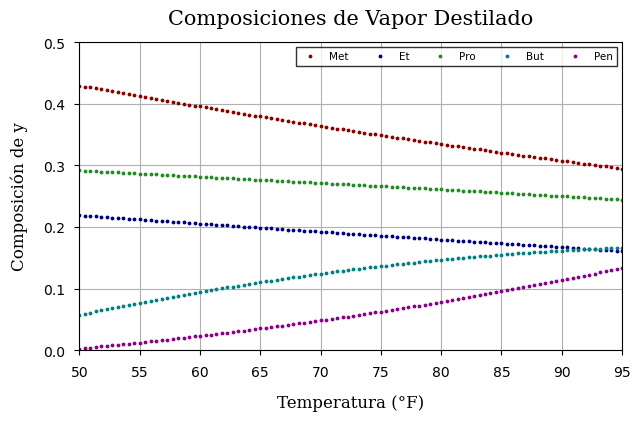

In [56]:
plt.figure(figsize=(7,4)) 
plt.tick_params(axis='both', labelsize=10, pad=7)

plt.xlim(50,95)
plt.ylim(0,0.5)

plt.plot(Ts,ymet,'.',label='Met',ms=3.5,color='darkred')
plt.plot(Ts,yeta,'.',label='Et',ms=3.5,color='navy')
plt.plot(Ts,ypro,'.',label='Pro',ms=3.5,color='forestgreen')
plt.plot(Ts,ybut,'.',label='But',ms=3.5,color='teal')
plt.plot(Ts,ypen,'.',label='Pen',ms=3.5,color='darkmagenta')

plt.title('Composiciones de Vapor Destilado', fontsize=15, fontfamily='serif', pad=13)
plt.ylabel('Composición de y',fontsize=12, fontfamily='serif', labelpad=11)
plt.xlabel('Temperatura (°F)',fontsize=12, fontfamily='serif', labelpad=11)
plt.legend(loc='upper right', fontsize=7.5, ncol=5, fancybox=False, edgecolor='black')

plt.grid(True)

In [ ]:
x = np.array([0,0.02,0.06,0.1,0.14,0.18,0.22,0.26,0.3,0.34,0.38,0.42,0.46,0.5,0.54,0.58,0.62,0.66,0.7,0.74,0.78,0.82,0.86,0.9,0.94,1])
y = np.array([0,0.0455,0.132,0.209,0.28,0.344,0.404,0.4585,0.5075,0.5555,0.6,0.64,0.679,0.714,0.747,0.7765,0.8045,0.8345,0.8505,0.8785,0.9005,0.9215,0.9405,0.959,0.9765,1])
T = np.array([110.40,109.6,107.9,106.2,104.6,102.95,101.4,99.9,98.5,97.2,95.9,94.6,93.35,92.2,91.1,90.05,89,88,86.95,86,85,84.1,83.2,82.3,81.45,80.3])

In [ ]:
plt.figure(figsize=(5,5))
plt.plot(T,x)
plt.plot(T,y)
plt.grid(True)
plt.show()

In [ ]:
psat_benceno = 117.8953 #kpa
psat_tolueno = 46.0865 #kpa

In [ ]:

# Temperatura en Kelvin
T_kelvin = T + 273.15

# Presiones de saturación en kPa
psat_benceno = 117.8953
psat_tolueno = 46.0865

# Constante de los gases (R) en L·kPa/(K·mol)
R = 8.314  # J/(mol·K) convertido a L·kPa/(K·mol)

# Cálculo del factor de corrección de Ki
Ki = x / y

# Cálculo de la pendiente de las líneas de operación
m = (Ki - 1) / (Ki + (R * T_kelvin) / (psat_benceno - psat_tolueno))

# Línea de equilibrio
x_eq = np.linspace(0, 1, 26)
y_eq = x_eq / (1 + (R * T_kelvin) / (psat_benceno - psat_tolueno))

# Graficar el diagrama de equilibrio líquido-vapor (LV) y las líneas de operación
plt.figure(figsize=(8, 6))
plt.plot(x_eq, y_eq, label="Línea de Equilibrio LV")
plt.plot(x_eq, m * x_eq + 1, label="Líneas de Operación")
plt.xlabel("Fracción molar de Benceno (x)")
plt.ylabel("Fracción molar de Tolueno (y)")
plt.title("Diagrama de Equilibrio LV y Líneas de Operación")
plt.legend()
plt.grid()
plt.show()

# Contar el número de etapas teóricas
num_etapas = np.where(x_eq <= x_eq - m * x_eq)[0][0]
print("Número de etapas teóricas requeridas:", num_etapas)
